<a href="https://colab.research.google.com/github/freddy-7/TI3002C/blob/main/9_Regresion_Logistica.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Cargamos librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    accuracy_score,
    recall_score,
    f1_score,
    classification_report
)

In [2]:
df=pd.read_csv("Titanic.csv")

In [3]:
df.head()

,Unnamed: 0,Survived,Pclass,Sex,Age,Sibsp,Parch,Fare,Embarked,Class,Who,Adult_male,Deck,Embark_town,Alive,Alone
0,0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [4]:
# Revisamos los valores de la variable objetivo
df['Class'].value_counts(dropna=False)

Class
Third     491
First     216
Second    184
Name: count, dtype: int64

In [5]:
# Eliminamos los registros que no tienen categoría objetivo
# y rellenamos los valores nulos de las variables predictoras
df = df.dropna(subset=['Class']).copy()
df['Age'] = df['Age'].fillna(df['Age'].median())
df['Fare'] = df['Fare'].fillna(df['Fare'].median())

In [6]:
# Declaramos las variables dependientes e independientes
# No incluimos Pclass porque representa la misma información que Class
Vars_Indep = df[['Age', 'Fare']]
Var_Dep = df['Class']

In [7]:
#Redefinimos las variables 
X= Vars_Indep
y= Var_Dep

In [8]:
# Dividimos el conjunto de datos en entrenamiento y prueba
# stratify conserva, en lo posible, la proporción de cada clase
X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.3, random_state=42, stratify=y)

In [9]:
#Se escalan todos los datos
escalar = StandardScaler()

In [10]:
# Ajustamos el escalador con los datos de entrenamiento
# y aplicamos la misma transformación a los datos de prueba
X_train = escalar.fit_transform(X_train)
X_test = escalar.transform(X_test)

In [11]:
# Definimos el algoritmo de regresión logística multinomial
# Con más de dos clases, scikit-learn ajusta el modelo multinomial
algoritmo = LogisticRegression(
    solver='lbfgs',
    max_iter=1000
)

In [12]:
#Entrenamos el modelo
algoritmo.fit(X_train, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is '

In [13]:
#Realizamos una predicción
y_pred = algoritmo.predict(X_test) 
y_pred

array(['Third', 'Third', 'Third', 'Third', 'First', 'Third', 'First',
       'Third', 'Third', 'Third', 'First', 'Third', 'Third', 'First',
       'Third', 'Third', 'First', 'Third', 'Third', 'Third', 'First',
       'Third', 'Third', 'Third', 'Third', 'Third', 'Third', 'Third',
       'Third', 'Third', 'Third', 'First', 'First', 'Third', 'Third',
       'First', 'Third', 'Third', 'First', 'Third', 'First', 'Third',
       'Third', 'Second', 'First', 'First', 'Third', 'Third', 'Third',
       'Third', 'First', 'Second', 'Third', 'Third', 'Third', 'Third',
       'Third', 'Second', 'Third', 'Third', 'First', 'Third', 'Third',
       'Third', 'Third', 'Third', 'Third', 'Third', 'Third', 'Third',
       'Third', 'Third', 'First', 'First', 'Third', 'Third', 'Third',
       'Third', 'Third', 'Third', 'Third', 'First', 'Third', 'Third',
       'Third', 'First', 'First', 'First', 'First', 'Third', 'Third',
       'Second', 'First', 'Third', 'Third', 'Third', 'First', 'Third',
       'First', 

In [14]:
# Consultamos las categorías que predice el modelo
print('Clases del modelo:')
print(algoritmo.classes_)

Clases del modelo:
['First' 'Second' 'Third']


In [15]:
# Verificamos la matriz de confusión
matriz = confusion_matrix(y_test, y_pred, labels=algoritmo.classes_)
print('Matriz de confusión:')
print(matriz)

Matriz de confusión:
[[ 52   1  12]
 [  5   3  47]
 [  9   3 136]]


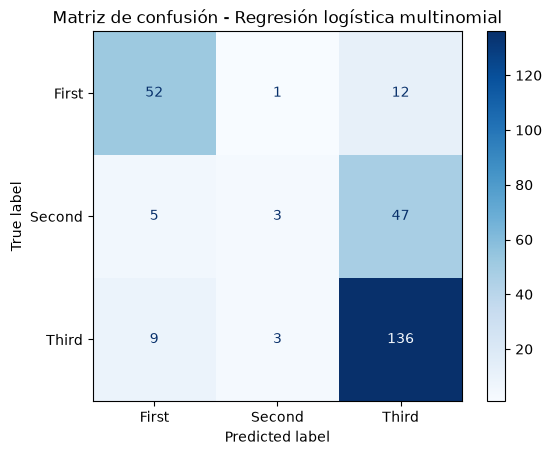

In [16]:
# Visualizamos la matriz de confusión
disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=algoritmo.classes_
)
disp.plot(cmap='Blues', values_format='d')
plt.title('Matriz de confusión - Regresión logística multinomial')
plt.show()

In [17]:
# Calculamos la precisión del modelo
# average='weighted' considera el número de observaciones de cada clase
#precision = precision_score(y_test, y_pred, average='weighted', zero_division=0)
precision = precision_score(y_test, y_pred, labels=['First'], average=None, zero_division=0)
print('Precisión ponderada del modelo:')
print(precision)

Precisión ponderada del modelo:
[0.78787879]


In [18]:
# Calculamos la exactitud del modelo
exactitud = accuracy_score(y_test, y_pred)
print('Exactitud del modelo:')
print(exactitud)

Exactitud del modelo:
0.7126865671641791


In [19]:
# Calculamos la sensibilidad (recall) ponderada
#sensibilidad = recall_score(y_test, y_pred, average='weighted', zero_division=0)
sensibilidad = recall_score(y_test, y_pred, labels=['First'], average=None, zero_division=0)
print('Sensibilidad ponderada del modelo:')
print(sensibilidad)

Sensibilidad ponderada del modelo:
[0.8]


In [20]:
# Calculamos el puntaje F1 ponderado
puntajef1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)
print('Puntaje F1 ponderado del modelo:')
print(puntajef1)

Puntaje F1 ponderado del modelo:
0.6503360655490905


In [21]:
# Reporte de clasificación por cada categoría
print(classification_report(y_test, y_pred, zero_division=0))

              precision    recall  f1-score   support

       First       0.79      0.80      0.79        65
      Second       0.43      0.05      0.10        55
       Third       0.70      0.92      0.79       148

    accuracy                           0.71       268
   macro avg       0.64      0.59      0.56       268
weighted avg       0.66      0.71      0.65       268



In [22]:
# Probabilidades estimadas para cada categoría
probabilidades = algoritmo.predict_proba(X_test)
df_probabilidades = pd.DataFrame(
    probabilidades,
    columns=[f'Probabilidad_{clase}' for clase in algoritmo.classes_]
)
df_probabilidades.head()

,Probabilidad_First,Probabilidad_Second,Probabilidad_Third
0,0.205789,0.350030,0.444181
1,0.191432,0.332459,0.476109
2,0.308377,0.319513,0.372111
3,0.051189,0.253640,0.695171
4,0.415818,0.323860,0.260322


In [23]:
# Comparamos la categoría real con la categoría predicha
comparacion = pd.DataFrame({
    'Clase real': y_test.reset_index(drop=True),
    'Clase predicha': pd.Series(y_pred)
})
comparacion.head(10)

,Clase real,Clase predicha
0,First,Third
1,Third,Third
2,Second,Third
3,Third,Third
4,First,First
5,Third,Third
6,Third,First
7,Third,Third
8,Third,Third
9,Third,Third
